# 05 v2 · Fase 1 con rezagos sin el día de programa

Misma especificación que `05_fase1` (PPML con efectos fijos de SKU, día de la semana y mes; errores agrupados por SKU y semana; corrección de Benjamini‑Hochberg en los efectos de clase y categoría), con **dos cambios en las categorías con programa semanal fijo** (MEATS, POULTRY, DELI y PRODUCE):

1. **Rezagos sin el día de programa.** En `05_fase1` el día de programa se excluye de la muestra, pero sigue contando como promoción dentro de los bloques de rezagos (`_l1_3`, `_l4_6`) de la promoción propia, de la clase y del resto de la categoría, porque `03_exposiciones` los calcula con `onpromotion` sin distinguir el programa. Aquí se recalculan contando el día de programa como **sin promoción**. Así, el día y los rezagos miden lo mismo: la **promoción fuera del programa** (D‑26).
2. **Campaña de MEATS.** Se excluye la campaña del 3 al 21 de junio de 2017 (casi todo el surtido en promoción fuera del programa durante tres semanas; el 71 % de los SKU‑días en promoción de MEATS fuera del programa) y los 6 días de operación siguientes, cuyos rezagos todavía la tocan. Se controla con el parámetro `ventanas_excluidas`.

Las seis categorías sin programa no cambian: sus resultados deben coincidir con los de `05_fase1` (se verifica en el Paso 8).

**Estado:** propuesta pendiente de aprobación del profesor guía. Cambia la implementación de D‑26 ("las variables de exposición no se recodifican").

| | |
|---|---|
| **Entrada** | `panel_t44_sku_dia.parquet`, `exposiciones_t44_sku_dia.parquet`, `calendario_t44.csv` |
| **Tablas** | `fase1v2_coeficientes.csv`, `fase1v2_efecto_neto.csv` |
| **Figuras** | `fase1v2_grafico_efectos.png`, `fase1v2_tabla1_efecto_propio.png`, `fase1v2_tabla2_misma_clase.png`, `fase1v2_tabla3_otras_clases.png`, `fase1v2_tabla4_efecto_neto.png` |

Ojo con los nombres: `fase1_coeficientes_v2.csv` es la salida del `05_fase1` original; la de este notebook es `fase1v2_coeficientes.csv`.

## Paso 1. Librerías y parámetros

In [1]:
# ------------------------------------------------------------------------------------------------------------
# Este notebook estima la fase 1 con los rezagos de las categorías con programa semanal fijo calculados sin el
# día de programa, y genera las tablas y figuras de resultados (como 06_figuras_poster).
# ------------------------------------------------------------------------------------------------------------
# Implementación: grupo de tesis (a partir de 05_fase1 y 06_figuras_poster)
# Fecha de versión: 2026-11-10
# ------------------------------------------------------------------------------------------------------------

# Librerías
# ------------------------------------------------------------------------------------------------------------
%pip install pyfixest==0.60.0
import os

import numpy as np
import pandas as pd
import pyfixest as pf
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests

# Parámetros del modelo (iguales a 05_fase1)
# ------------------------------------------------------------------------------------------------------------
categorias = [
    "BEVERAGES", "GROCERY I", "CLEANING", "DAIRY", "BREAD/BAKERY", "LIQUOR,WINE,BEER",
    "MEATS", "POULTRY", "DELI", "PRODUCE",
]

# D-14: promoción propia, de la clase y del resto de la categoría, cada una con sus bloques de rezagos
regresores_promocion = [
    "onpromotion", "onpromotion_l1_3", "onpromotion_l4_6",
    "promo_clase_otros", "promo_clase_otros_l1_3", "promo_clase_otros_l4_6",
    "promo_cat_otras_clases", "promo_cat_otras_clases_l1_3", "promo_cat_otras_clases_l4_6",
]

# D-10 y D-13: controles de calendario
controles_calendario = [
    "dia_libre", "adicional", "dia_laboral_recuperado", "evento_comercial", "evento_otro", "dia_pago", "post_pago",
]

variable_dependiente = "unit_sales_ppml"   # D-08, D-20
efectos_fijos = "item_nbr + dow + mes"     # D-16
agrupamiento = "item_nbr + semana"         # D-15

formula = f"{variable_dependiente} ~ {' + '.join(regresores_promocion + controles_calendario)} | {efectos_fijos}"

# Parámetros nuevos de esta versión
# ------------------------------------------------------------------------------------------------------------
# D-14: bloques de rezagos (días de operación anteriores), los mismos de 03_exposiciones
bloques = {"l1_3": [1, 2, 3], "l4_6": [4, 5, 6]}
columnas_rezagos = [c for c in regresores_promocion if c.endswith(tuple(bloques))]

# Ventanas (inicio, fin) que se excluyen de la estimación de una categoría; también se excluyen los días de
# operación siguientes cuyos rezagos tocan la ventana. Para no excluir nada: ventanas_excluidas = {}
ventanas_excluidas = {"MEATS": [("2017-06-03", "2017-06-21")]}

# Formato de las figuras (igual que 06_figuras_poster)
decimales = 1
color_neutro, color_negativo, color_positivo = "#1f5fa6", "#c0392b", "#27ae60"
color_significativo, color_cabecera = "#8fb5db", "#13213c"

# Rutas
# ------------------------------------------------------------------------------------------------------------
ruta_procesados = os.path.join("..", "data", "procesados")
ruta_tablas = os.path.join("resultados", "tablas")
ruta_figuras = os.path.join("resultados", "figuras")
os.makedirs(ruta_tablas, exist_ok=True)
os.makedirs(ruta_figuras, exist_ok=True)
prefijo = "fase1v2"

Defaulting to user installation because normal site-packages is not writeable


Note: you may need to restart the kernel to use updated packages.


## Paso 2. Importar los datos

Los mismos tres archivos que `05_fase1`. Al calendario se le agrega el índice de día de operación `t` (0 a 589), igual que en `03_exposiciones`, para desplazar por días de operación: el día anterior al 26‑12‑2016 es el 24‑12‑2016, porque la tienda no abre el 25.

In [2]:
panel = pd.read_parquet(os.path.join(ruta_procesados, "panel_t44_sku_dia.parquet"))
exposiciones = pd.read_parquet(os.path.join(ruta_procesados, "exposiciones_t44_sku_dia.parquet"))
calendario = pd.read_csv(os.path.join(ruta_procesados, "calendario_t44.csv"), parse_dates=["date"])

# Numerar los días con operación (t = 0, ..., 589), igual que en 03_exposiciones
calendario = calendario.sort_values("date").reset_index(drop=True)
calendario["t"] = np.arange(len(calendario))

# Identificar las categorías con programa semanal fijo (tienen algún SKU-día de programa)
skus_programa = exposiciones.loc[exposiciones["dia_programa"], "item_nbr"].unique()
familias_programa = set(panel.loc[panel["item_nbr"].isin(skus_programa), "family"].astype(str))
categorias_programa = [c for c in categorias if c in familias_programa]

print(f"panel:        {len(panel):,} SKU-días")
print(f"exposiciones: {len(exposiciones):,} SKU-días")
print(f"calendario:   {len(calendario):,} días")
print(f"categorías con programa entre las modeladas: {categorias_programa}")

panel:        1,935,758 SKU-días
exposiciones: 1,935,758 SKU-días
calendario:   590 días
categorías con programa entre las modeladas: ['MEATS', 'POULTRY', 'DELI', 'PRODUCE']


## Paso 3. Rezagos sin el día de programa

Los bloques de rezagos son el **promedio** de una variable en los días de operación anteriores: `l1_3` = días 1 a 3 anteriores, `l4_6` = días 4 a 6 anteriores. La única diferencia con `03_exposiciones` es qué cuenta como promoción. Ejemplo con un SKU de PRODUCE (programa los miércoles) que solo estuvo en promoción por el programa, visto un sábado:

| Rezago 1–3 del sábado (viernes, jueves, miércoles) | Valor |
|---|---|
| `05_fase1`: el miércoles cuenta como promoción | 1/3 |
| Esta versión: el miércoles cuenta como sin promoción | 0 |

Con el cambio, la proporción de los otros SKUs de la clase y del resto de la categoría también se calcula con la promoción fuera del programa. El resto de las reglas son las de `03_exposiciones`:

- La ventana del terremoto (D‑09) queda nula, así que un bloque que la toca queda nulo.
- Fuera del período (antes del 2016‑01‑02) el bloque queda nulo.
- Fuera de la ventana de vida del SKU, la promoción propia vale 0 y las exposiciones de clase y categoría son nulas.

**Verificación.** Si se cuenta el día de programa como promoción (`contar_programa=True`), la función debe reproducir exactamente las columnas de `03_exposiciones`. El `assert` lo comprueba en las cuatro categorías con programa.

In [3]:
def promedio_bloques(datos: pd.DataFrame, columna: str, relleno_fuera_ventana: float) -> dict:
    """
    Esta función calcula el promedio de una variable SKU-día en cada bloque de días de operación anteriores, con
    las mismas reglas que 03_exposiciones.

    :param datos:                   un DataFrame de una categoría ordenado por SKU y fecha, con las columnas
                                    item_nbr, t (índice del día de operación) y ventana_terremoto.
    :param columna:                 el nombre de la variable a desplazar.
    :param relleno_fuera_ventana:   el valor para los días fuera de la ventana de vida del SKU (0.0 o np.nan).
    :return:                        un diccionario {sufijo del bloque: serie con el promedio del bloque}.
    """

    # Anular los días de la ventana del terremoto para que no entren a ningún bloque
    valores = datos[columna].astype(float).where(~datos["ventana_terremoto"])
    por_sku = valores.groupby(datos["item_nbr"])

    # Posición de cada fila dentro de la ventana de vida del SKU
    pos_inicio = datos.groupby("item_nbr").cumcount()

    resultado = {}
    for sufijo, desplazamientos in bloques.items():
        desplazadas = []
        for k in desplazamientos:
            # Desplazar k días de operación; rellenar fuera de la ventana de vida y anular fuera del período
            s = por_sku.shift(k).where(pos_inicio >= k, relleno_fuera_ventana).where(datos["t"] - k >= 0)
            desplazadas.append(s)

        # Promediar el bloque; si falta algún día, el bloque queda nulo
        resultado[sufijo] = pd.concat(desplazadas, axis=1).mean(axis=1, skipna=False).astype("float32")

    return resultado


def rezagos_fuera_programa(datos: pd.DataFrame, contar_programa: bool = False) -> pd.DataFrame:
    """
    Esta función recalcula los bloques de rezagos de la promoción propia, de la clase y del resto de la categoría
    para una categoría. Con contar_programa=False, la promoción del día de programa cuenta como cero.

    :param datos:               un DataFrame con todos los SKU-días de una categoría (incluidos los días de
                                programa y de la ventana del terremoto), con las columnas item_nbr, date, class,
                                onpromotion, dia_programa, t y ventana_terremoto.
    :param contar_programa:     si es True, el día de programa cuenta como promoción y se reproducen los rezagos
                                de 03_exposiciones (sirve para verificar). Default is False.
    :return:                    un DataFrame con item_nbr, date y las seis columnas de rezagos.
    """

    # Ordenar por SKU y fecha, y verificar que los días de operación sean consecutivos dentro de cada SKU
    d = datos.sort_values(["item_nbr", "date"]).reset_index(drop=True)
    assert (d.groupby("item_nbr")["t"].diff().dropna() == 1).all(), "faltan días dentro de la ventana de algún SKU"

    # Definir la promoción que entra a los rezagos: fuera del programa (o toda, para verificar)
    if contar_programa:
        d["promo"] = d["onpromotion"].astype(int)
    else:
        d["promo"] = (d["onpromotion"] & ~d["dia_programa"]).astype(int)

    # Contar SKUs activos y en promoción por clase y por categoría en cada día
    por_clase = d.groupby(["class", "date"], observed=True)["promo"]
    n_activos_clase = por_clase.transform("size")
    n_promo_clase = por_clase.transform("sum")
    por_categoria = d.groupby("date", observed=True)["promo"]
    n_activos_cat = por_categoria.transform("size")
    n_promo_cat = por_categoria.transform("sum")

    # Calcular la proporción en promoción de los otros SKUs de la clase y de las otras clases de la categoría
    otros_clase = n_activos_clase - 1
    d["clase"] = ((n_promo_clase - d["promo"]) / otros_clase).where(otros_clase > 0)
    otras_clases = n_activos_cat - n_activos_clase
    d["cat"] = ((n_promo_cat - n_promo_clase) / otras_clases).where(otras_clases > 0)

    # Promediar cada variable en los bloques de rezagos
    salida = d[["item_nbr", "date"]].copy()
    variables = [
        ("promo", "onpromotion", 0.0),
        ("clase", "promo_clase_otros", np.nan),
        ("cat", "promo_cat_otras_clases", np.nan),
    ]
    for columna, nombre, relleno in variables:
        for sufijo, serie in promedio_bloques(d, columna, relleno).items():
            salida[f"{nombre}_{sufijo}"] = serie

    return salida

In [4]:
# Verificar que, contando el día de programa, la función reproduce los rezagos de 03_exposiciones
for categoria in categorias_programa:
    datos_cat = (
        panel.loc[panel["family"] == categoria]
        .merge(exposiciones, on=["item_nbr", "date"], how="left")
        .merge(calendario, on="date", how="left")
    )
    reconstruidos = rezagos_fuera_programa(datos_cat, contar_programa=True).merge(
        datos_cat[["item_nbr", "date"] + columnas_rezagos], on=["item_nbr", "date"], suffixes=("_nuevo", "")
    )
    for columna in columnas_rezagos:
        nuevo, original = reconstruidos[f"{columna}_nuevo"], reconstruidos[columna]
        assert (nuevo.isna() == original.isna()).all(), f"{categoria}, {columna}: los nulos no coinciden"
        assert (nuevo - original).abs().max() < 1e-5, f"{categoria}, {columna}: los valores no coinciden"
    print(f"{categoria:8s} la reconstrucción coincide con 03_exposiciones en las {len(columnas_rezagos)} columnas")

MEATS    la reconstrucción coincide con 03_exposiciones en las 6 columnas


POULTRY  la reconstrucción coincide con 03_exposiciones en las 6 columnas
DELI     la reconstrucción coincide con 03_exposiciones en las 6 columnas


PRODUCE  la reconstrucción coincide con 03_exposiciones en las 6 columnas


## Paso 4. Armar la base de una categoría

Igual que en `05_fase1`, con dos diferencias:

- En las categorías con programa, las seis columnas de rezagos se reemplazan por las calculadas sin el día de programa.
- Se excluyen las ventanas de `ventanas_excluidas` y los 6 días de operación siguientes (en MEATS, del 3 al 27 de junio de 2017).

In [5]:
def dias_excluidos(categoria: str) -> pd.Series:
    """
    Esta función devuelve las fechas que se excluyen de la estimación de una categoría: las de sus ventanas en
    ventanas_excluidas y los días de operación siguientes cuyos rezagos tocan la ventana.

    :param categoria:   el nombre de la categoría (columna family).
    :return:            una serie con las fechas excluidas (vacía si la categoría no tiene ventanas).
    """

    rezago_maximo = max(max(desplazamientos) for desplazamientos in bloques.values())
    fechas = []
    for inicio, fin in ventanas_excluidas.get(categoria, []):
        # Días de la ventana y días de operación siguientes cuyos rezagos la tocan
        en_ventana = calendario["date"].between(pd.Timestamp(inicio), pd.Timestamp(fin))
        t_fin = calendario.loc[en_ventana, "t"].max()
        despues = calendario["t"].between(t_fin + 1, t_fin + rezago_maximo)
        fechas.append(calendario.loc[en_ventana | despues, "date"])

    return pd.concat(fechas) if fechas else pd.Series(dtype="datetime64[ns]")


def armar_base(categoria: str) -> pd.DataFrame:
    """
    Esta función arma la base de estimación de una categoría: une el panel, las exposiciones y el calendario,
    recalcula los rezagos sin el día de programa (si la categoría tiene programa) y excluye los días que no entran
    al modelo.

    :param categoria:   el nombre de la categoría (columna family).
    :return:            un DataFrame con una fila por SKU-día usada en la estimación.
    """

    # Unir las filas de la categoría con sus exposiciones (por SKU y fecha) y con el calendario (por fecha)
    base = panel.loc[panel["family"] == categoria]
    filas = len(base)
    base = base.merge(exposiciones, on=["item_nbr", "date"], how="left")
    base = base.merge(calendario, on="date", how="left")
    assert len(base) == filas, "una unión cambió el número de filas"

    # En las categorías con programa, reemplazar los rezagos por los calculados sin el día de programa
    if categoria in categorias_programa:
        nuevos = rezagos_fuera_programa(base)
        base = base.drop(columns=columnas_rezagos).merge(nuevos, on=["item_nbr", "date"], how="left")
        assert len(base) == filas, "el reemplazo de los rezagos cambió el número de filas"

    # Excluir la ventana del terremoto (D-09), los días de programa (A-03), las ventanas excluidas y las filas con
    # rezagos vacíos
    excluidas = base["date"].isin(dias_excluidos(categoria))
    base = base.loc[~base["ventana_terremoto"] & ~base["dia_programa"] & ~excluidas]
    base = base.dropna(subset=[variable_dependiente] + regresores_promocion).copy()

    # Pasar los indicadores a 0/1 para la fórmula
    base[["onpromotion"] + controles_calendario] = base[["onpromotion"] + controles_calendario].astype(int)

    return base

## Paso 5. Estimar las diez categorías

Para cada categoría se guardan los coeficientes de promoción (como en `05_fase1`), el **efecto neto** de la promoción propia y la prueba conjunta de los rezagos propios.

**Efecto neto** (`metodologia.tex`, fase 1): $e^{\beta_0+\beta_{1\text{-}3}+\beta_{4\text{-}6}}-1$, con su intervalo de 95 % calculado con la varianza de la suma de los tres coeficientes y una $t$ de $G-1$ grados de libertad (igual que los demás intervalos). Ojo con la lectura: suma efectos en logaritmos de distintos días, así que no es "el cambio % de las ventas de la semana".

**Prueba de rezagos** (Paso 8 de `05_fase1`): $H_0$: $\beta_{1\text{-}3} = \beta_{4\text{-}6} = 0$.

In [6]:
def tabla_coeficientes(modelo, base: pd.DataFrame, categoria: str) -> pd.DataFrame:
    """
    Esta función extrae los coeficientes de promoción de un modelo, con su valor p, su intervalo de 95 % y su
    efecto en porcentaje (igual que en 05_fase1).

    :param modelo:      un modelo estimado con pf.fepois.
    :param base:        la base con la que se estimó el modelo (para contar SKUs y semanas).
    :param categoria:   el nombre de la categoría, para identificar las filas.
    :return:            un DataFrame con una fila por variable de promoción.
    """

    # Coeficiente y error estándar agrupado por SKU y semana
    tabla = pd.DataFrame({"beta": modelo.coef()[regresores_promocion], "ee": modelo.se()[regresores_promocion]})

    # Valor p e intervalo de 95 % con una t de G - 1 grados de libertad (G: semanas, la dimensión más chica; D-15)
    grados_libertad = min(base["item_nbr"].nunique(), base["semana"].nunique()) - 1
    t_critico = stats.t.ppf(0.975, grados_libertad)
    tabla["p_valor"] = 2 * stats.t.sf(np.abs(tabla["beta"] / tabla["ee"]), grados_libertad)
    tabla["ic_inf"] = tabla["beta"] - t_critico * tabla["ee"]
    tabla["ic_sup"] = tabla["beta"] + t_critico * tabla["ee"]

    # Efecto en porcentaje: por unidad (0 a 1) y, para las proporciones S, por +10 puntos porcentuales
    tabla["efecto_pct"] = 100 * np.expm1(tabla["beta"])
    es_proporcion = tabla.index.str.startswith("promo_")
    tabla["efecto_10pp_pct"] = (100 * np.expm1(0.1 * tabla["beta"])).where(es_proporcion)

    tabla = tabla.rename_axis("coeficiente").reset_index()
    tabla.insert(0, "categoria", categoria)
    return tabla


def efecto_neto(modelo, base: pd.DataFrame) -> dict:
    """
    Esta función calcula el efecto neto de la promoción propia, exp(beta_0 + beta_l1_3 + beta_l4_6) - 1, con su
    intervalo de 95 % y su valor p.

    :param modelo:      un modelo estimado con pf.fepois.
    :param base:        la base con la que se estimó el modelo (para los grados de libertad).
    :return:            un diccionario con la suma de los coeficientes, su error estándar, su valor p y el efecto
                        neto en porcentaje con su intervalo.
    """

    # Varianza de la suma de los tres coeficientes de la promoción propia
    coef = modelo.coef()
    vcov = pd.DataFrame(np.asarray(modelo._vcov), index=coef.index, columns=coef.index)
    pesos = pd.Series(0.0, index=coef.index)
    pesos[["onpromotion", "onpromotion_l1_3", "onpromotion_l4_6"]] = 1.0
    suma = float(pesos @ coef)
    ee = float(np.sqrt(pesos @ vcov @ pesos))

    # Valor p e intervalo con la misma t de G - 1 grados de libertad
    grados_libertad = min(base["item_nbr"].nunique(), base["semana"].nunique()) - 1
    t_critico = stats.t.ppf(0.975, grados_libertad)

    return {
        "suma_beta":        suma,
        "ee":               ee,
        "p_valor":          2 * stats.t.sf(abs(suma / ee), grados_libertad),
        "efecto_neto_pct":  100 * np.expm1(suma),
        "ic_inf_pct":       100 * np.expm1(suma - t_critico * ee),
        "ic_sup_pct":       100 * np.expm1(suma + t_critico * ee),
    }


def prueba_rezagos(modelo) -> float:
    """
    Esta función prueba si los dos rezagos de la promoción propia son cero a la vez (prueba de Wald).

    :param modelo:      un modelo estimado con pf.fepois.
    :return:            el valor p de la prueba (chi cuadrado con 2 grados de libertad).
    """

    nombres = list(modelo.coef().index)
    posiciones = [nombres.index("onpromotion_l1_3"), nombres.index("onpromotion_l4_6")]
    b = modelo.coef().to_numpy()[posiciones]
    V = np.asarray(modelo._vcov)[np.ix_(posiciones, posiciones)]
    estadistico = float(b @ np.linalg.solve(V, b))
    return float(stats.chi2.sf(estadistico, df=2))

In [7]:
modelos = {}
tablas = []
netos = []
for categoria in categorias:
    base_j = armar_base(categoria)
    modelos[categoria] = pf.fepois(formula, data=base_j, vcov={"CRV1": agrupamiento})

    # Coeficientes de promoción, con el tamaño de la muestra
    tabla_j = tabla_coeficientes(modelos[categoria], base_j, categoria)
    tabla_j["n_obs"] = len(modelos[categoria].resid())
    tabla_j["n_skus"] = base_j["item_nbr"].nunique()
    tabla_j["n_dias"] = base_j["date"].nunique()
    tabla_j["sku_dias_promo"] = int(base_j["onpromotion"].sum())
    tablas.append(tabla_j)

    # Efecto neto y prueba conjunta de los rezagos propios
    neto_j = efecto_neto(modelos[categoria], base_j)
    neto_j.update(
        {
            "categoria":        categoria,
            "con_programa":     categoria in categorias_programa,
            "dia_pct":          100 * np.expm1(modelos[categoria].coef()["onpromotion"]),
            "rezago_1_3_pct":   100 * np.expm1(modelos[categoria].coef()["onpromotion_l1_3"]),
            "rezago_4_6_pct":   100 * np.expm1(modelos[categoria].coef()["onpromotion_l4_6"]),
            "p_wald_rezagos":   prueba_rezagos(modelos[categoria]),
        }
    )
    netos.append(neto_j)

    print(f"{categoria:17s} base: {len(base_j):>7,}   usadas por el modelo: {tabla_j['n_obs'].iloc[0]:>7,}   "
          f"SKU-días en promoción: {tabla_j['sku_dias_promo'].iloc[0]:>6,}")

coeficientes = pd.concat(tablas, ignore_index=True)
efectos_netos = pd.DataFrame(netos)

/sessions/rcw-01pbchvzf4n2etm4kqmsoou5/.local/lib/python3.10/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(


BEVERAGES         base: 258,915   usadas por el modelo: 258,914   SKU-días en promoción: 19,386


/sessions/rcw-01pbchvzf4n2etm4kqmsoou5/.local/lib/python3.10/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 2 singleton fixed effect(s) dropped from the model.
  warnings.warn(


GROCERY I         base: 556,533   usadas por el modelo: 556,531   SKU-días en promoción: 38,391


/sessions/rcw-01pbchvzf4n2etm4kqmsoou5/.local/lib/python3.10/site-packages/pyfixest/estimation/models/_result_accessor_mixin.py:85: RuntimeWarning: invalid value encountered in sqrt
  self._se = np.sqrt(np.diagonal(self._vcov))
/sessions/rcw-01pbchvzf4n2etm4kqmsoou5/.local/lib/python3.10/site-packages/pyfixest/estimation/models/_result_accessor_mixin.py:85: RuntimeWarning: invalid value encountered in sqrt
  self._se = np.sqrt(np.diagonal(self._vcov))
/sessions/rcw-01pbchvzf4n2etm4kqmsoou5/.local/lib/python3.10/site-packages/pyfixest/estimation/models/_result_accessor_mixin.py:85: RuntimeWarning: invalid value encountered in sqrt
  self._se = np.sqrt(np.diagonal(self._vcov))
/sessions/rcw-01pbchvzf4n2etm4kqmsoou5/.local/lib/python3.10/site-packages/pyfixest/estimation/models/_result_accessor_mixin.py:85: RuntimeWarning: invalid value encountered in sqrt
  self._se = np.sqrt(np.diagonal(self._vcov))


CLEANING          base: 197,454   usadas por el modelo: 197,454   SKU-días en promoción: 13,711


... (5 outputs left out)

/sessions/rcw-01pbchvzf4n2etm4kqmsoou5/.local/lib/python3.10/site-packages/pyfixest/estimation/models/_result_accessor_mixin.py:85: RuntimeWarning: invalid value encountered in sqrt
  self._se = np.sqrt(np.diagonal(self._vcov))
/sessions/rcw-01pbchvzf4n2etm4kqmsoou5/.local/lib/python3.10/site-packages/pyfixest/estimation/models/_result_accessor_mixin.py:85: RuntimeWarning: invalid value encountered in sqrt
  self._se = np.sqrt(np.diagonal(self._vcov))
/sessions/rcw-01pbchvzf4n2etm4kqmsoou5/.local/lib/python3.10/site-packages/pyfixest/estimation/models/_result_accessor_mixin.py:85: RuntimeWarning: invalid value encountered in sqrt
  self._se = np.sqrt(np.diagonal(self._vcov))
/sessions/rcw-01pbchvzf4n2etm4kqmsoou5/.local/lib/python3.10/site-packages/pyfixest/estimation/models/_result_accessor_mixin.py:85: RuntimeWarning: invalid value encountered in sqrt
  self._se = np.sqrt(np.diagonal(self._vcov))


/sessions/rcw-01pbchvzf4n2etm4kqmsoou5/.local/lib/python3.10/site-packages/pyfixest/estimation/models/_result_accessor_mixin.py:85: RuntimeWarning: invalid value encountered in sqrt
  self._se = np.sqrt(np.diagonal(self._vcov))
/sessions/rcw-01pbchvzf4n2etm4kqmsoou5/.local/lib/python3.10/site-packages/pyfixest/estimation/models/_result_accessor_mixin.py:85: RuntimeWarning: invalid value encountered in sqrt
  self._se = np.sqrt(np.diagonal(self._vcov))
/sessions/rcw-01pbchvzf4n2etm4kqmsoou5/.local/lib/python3.10/site-packages/pyfixest/estimation/models/_result_accessor_mixin.py:85: RuntimeWarning: invalid value encountered in sqrt
  self._se = np.sqrt(np.diagonal(self._vcov))
/sessions/rcw-01pbchvzf4n2etm4kqmsoou5/.local/lib/python3.10/site-packages/pyfixest/estimation/models/_result_accessor_mixin.py:85: RuntimeWarning: invalid value encountered in sqrt
  self._se = np.sqrt(np.diagonal(self._vcov))


DELI              base:  33,486   usadas por el modelo:  33,486   SKU-días en promoción:  3,166


PRODUCE           base: 114,296   usadas por el modelo: 114,296   SKU-días en promoción:  2,808


## Paso 6. Corrección por comparaciones múltiples (D‑15)

Igual que en `05_fase1`: Benjamini‑Hochberg sobre los efectos de clase y categoría de las diez categorías (10 × 6 = 60). `p_bh` < 0,05 es el criterio para afirmar que un efecto cruzado existe. Los efectos propios no se corrigen.

In [8]:
# Ajustar los valores p de los efectos de clase y categoría (variables S)
es_cruzado = coeficientes["coeficiente"].str.startswith("promo_")
coeficientes.loc[es_cruzado, "p_bh"] = multipletests(
    coeficientes.loc[es_cruzado, "p_valor"], alpha=0.05, method="fdr_bh"
)[1]

coeficientes.to_csv(os.path.join(ruta_tablas, f"{prefijo}_coeficientes.csv"), index=False)
print(f"Efectos cruzados corregidos: {es_cruzado.sum()}")

with pd.option_context("display.float_format", "{:,.3f}".format, "display.max_rows", 100):
    display(coeficientes.drop(columns=["n_obs", "n_skus", "n_dias", "sku_dias_promo"]).set_index(["categoria", "coeficiente"]))

Efectos cruzados corregidos: 60


beta    ee  p_valor  ic_inf  \
categoria        coeficiente                                                 
BEVERAGES        onpromotion                  0.469 0.058    0.000   0.353   
                 onpromotion_l1_3             0.238 0.062    0.000   0.115   
                 onpromotion_l4_6            -0.105 0.063    0.100  -0.229   
                 promo_clase_otros           -0.306 0.114    0.009  -0.533   
                 promo_clase_otros_l1_3      -0.020 0.120    0.871  -0.259   
                 promo_clase_otros_l4_6       0.079 0.101    0.441  -0.123   
                 promo_cat_otras_clases      -0.633 0.361    0.084  -1.353   
                 promo_cat_otras_clases_l1_3  0.272 0.413    0.513  -0.551   
                 promo_cat_otras_clases_l4_6  0.406 0.298    0.176  -0.186   
GROCERY I        onpromotion                  0.473 0.051    0.000   0.372   
                 onpromotion_l1_3             0.260 0.043    0.000   0.175   
                 onpromotion_l4_6            -0.011 0.043    0.801  -0.097   
                 promo_clase_otros           -0.226 0.072    0.002  -0.368   
                 promo_clase_otros_l1_3      -0.314 0.074    0.000  -0.460   
                 promo_clase_otros_l4_6       0.169 0.075    0.027   0.020   
                 promo_cat_otras_clases      -0.739 0.395    0.065  -1.525   
                 promo_cat_otras_clases_l1_3 -0.400 0.661    0.547  -1.717   
                 promo_cat_otras_clases_l4_6  1.266 0.608    0.041   0.056   
CLEANING         onpromotion                  0.636 0.074    0.000   0.489   
                 onpromotion_l1_3             0.233 0.103    0.026   0.028   
                 onpromotion_l4_6            -0.024 0.069    0.727  -0.162   
                 promo_clase_otros           -0.310 0.135    0.025  -0.580   
                 promo_clase_otros_l1_3      -0.487 0.198    0.016  -0.881   
                 promo_clase_otros_l4_6       0.113 0.149    0.451  -0.184   
                 promo_cat_otras_clases      -0.490 0.368    0.187  -1.221   
                 promo_cat_otras_clases_l1_3  0.301 0.411    0.467  -0.518   
                 promo_cat_otras_clases_l4_6  0.774 0.428    0.075  -0.079   
DAIRY            onpromotion                  0.345 0.023    0.000   0.300   
                 onpromotion_l1_3             0.087 0.021    0.000   0.046   
                 onpromotion_l4_6             0.031 0.017    0.077  -0.003   
                 promo_clase_otros           -0.101 0.045    0.027  -0.191   
                 promo_clase_otros_l1_3      -0.043 0.051    0.407  -0.144   
                 promo_clase_otros_l4_6      -0.015 0.045    0.736  -0.105   
                 promo_cat_otras_clases      -0.107 0.204    0.603  -0.513   
                 promo_cat_otras_clases_l1_3  0.205 0.342    0.551  -0.476   
                 promo_cat_otras_clases_l4_6 -0.286 0.187    0.131  -0.659   
BREAD/BAKERY     onpromotion                  0.375 0.058    0.000   0.258   
                 onpromotion_l1_3             0.144 0.066    0.032   0.013   
                 onpromotion_l4_6             0.099 0.075    0.192  -0.051   
                 promo_clase_otros           -0.075 0.089    0.402  -0.253   
                 promo_clase_otros_l1_3      -0.049 0.084    0.560  -0.217   
                 promo_clase_otros_l4_6      -0.140 0.099    0.162  -0.337   
                 promo_cat_otras_clases      -0.664 0.231    0.005  -1.123   
                 promo_cat_otras_clases_l1_3  0.409 0.363    0.263  -0.313   
                 promo_cat_otras_clases_l4_6 -0.175 0.253    0.490  -0.679   
LIQUOR,WINE,BEER onpromotion                  0.560 0.060    0.000   0.439   
                 onpromotion_l1_3             0.135 0.073    0.070  -0.012   
                 onpromotion_l4_6            -0.008 0.102    0.938  -0.214   
                 promo_clase_otros            0.761 0.217    0.001   0.324   
                 promo_clase_otros_l1_3       0.333 0.140    0.021   

## Paso 7. Efecto neto y prueba de rezagos

In [9]:
columnas_neto = [
    "categoria", "con_programa", "dia_pct", "rezago_1_3_pct", "rezago_4_6_pct", "p_wald_rezagos",
    "suma_beta", "ee", "efecto_neto_pct", "ic_inf_pct", "ic_sup_pct", "p_valor",
]
efectos_netos = efectos_netos[columnas_neto]
efectos_netos.to_csv(os.path.join(ruta_tablas, f"{prefijo}_efecto_neto.csv"), index=False)
efectos_netos.set_index("categoria").round(3)

,con_programa,dia_pct,rezago_1_3_pct,rezago_4_6_pct,p_wald_rezagos,suma_beta,ee,efecto_neto_pct,ic_inf_pct,ic_sup_pct,p_valor
categoria,,,,,,,,,,,
BEVERAGES,False,59.816,26.923,-9.923,0.000,0.603,0.078,82.715,56.397,113.463,0.000
GROCERY I,False,60.429,29.653,-1.084,0.000,0.721,0.045,105.746,88.246,124.873,0.000
CLEANING,False,88.938,26.247,-2.398,0.014,0.845,0.068,132.809,103.399,166.472,0.000
DAIRY,False,41.216,9.128,3.100,0.000,0.463,0.030,58.883,49.720,68.607,0.000
BREAD/BAKERY,False,45.452,15.546,10.354,0.002,0.618,0.099,85.466,52.254,125.922,0.000
"LIQUOR,WINE,BEER",False,75.022,14.457,-0.803,0.065,0.687,0.165,98.717,42.477,177.159,0.000
MEATS,True,11.247,7.044,3.354,0.585,0.208,0.045,23.077,12.382,34.790,0.000
POULTRY,True,6.906,-5.035,1.718,0.894,0.032,0.109,3.268,-17.054,28.569,0.769
DELI,True,27.745,28.633,5.820,0.000,0.553,0.063,73.887,53.498,96.984,0.000


## Paso 8. Comparación con `05_fase1`

Las seis categorías sin programa deben dar exactamente lo mismo que en `05_fase1` (su muestra y sus variables no cambian); el `assert` lo comprueba. En las cuatro con programa se muestra cómo cambian el efecto del día y los rezagos.

In [10]:
# Leer los coeficientes de 05_fase1
anteriores = pd.read_csv(os.path.join(ruta_tablas, "fase1_coeficientes_v2.csv"))
comparacion = anteriores.merge(coeficientes, on=["categoria", "coeficiente"], suffixes=("_05", "_v2"))

# Verificar que las categorías sin programa no cambian
sin_programa = ~comparacion["categoria"].isin(categorias_programa)
diferencia_maxima = (comparacion.loc[sin_programa, "beta_05"] - comparacion.loc[sin_programa, "beta_v2"]).abs().max()
assert diferencia_maxima < 1e-6, f"las categorías sin programa cambiaron (diferencia máxima {diferencia_maxima})"
print(f"Categorías sin programa: idénticas a 05_fase1 (diferencia máxima en beta: {diferencia_maxima:.1e})")

# Mostrar el cambio en la promoción propia de las categorías con programa
propia = comparacion["coeficiente"].isin(["onpromotion", "onpromotion_l1_3", "onpromotion_l4_6"])
cambio = comparacion.loc[~sin_programa & propia, ["categoria", "coeficiente", "efecto_pct_05", "p_valor_05",
                                                   "efecto_pct_v2", "p_valor_v2"]]
cambio.set_index(["categoria", "coeficiente"]).round(3)

Categorías sin programa: idénticas a 05_fase1 (diferencia máxima en beta: 7.8e-12)


efecto_pct_05  p_valor_05  efecto_pct_v2  \
categoria coeficiente                                                  
MEATS     onpromotion               6.903       0.398         11.247   
          onpromotion_l1_3         20.054       0.081          7.044   
          onpromotion_l4_6          4.350       0.586          3.354   
POULTRY   onpromotion             -17.340       0.108          6.906   
          onpromotion_l1_3         47.048       0.012         -5.035   
          onpromotion_l4_6          1.837       0.828          1.718   
DELI      onpromotion              18.910       0.002         27.745   
          onpromotion_l1_3         43.964       0.000         28.633   
          onpromotion_l4_6          4.533       0.213          5.820   
PRODUCE   onpromotion             -47.218       0.000         20.283   
          onpromotion_l1_3        143.804       0.000          1.315   
          onpromotion_l4_6         34.375       0.000          7.665   

                            p_valor_v2  
categoria coeficiente                   
MEATS     onpromotion            0.180  
          onpromotion_l1_3       0.416  
          onpromotion_l4_6       0.681  
POULTRY   onpromotion            0.430  
          onpromotion_l1_3       0.663  
          onpromotion_l4_6       0.834  
DELI      onpromotion            0.000  
          onpromotion_l1_3       0.000  
          onpromotion_l4_6       0.122  
PRODUCE   onpromotion            0.000  
          onpromotion_l1_3       0.725  
          onpromotion_l4_6       0.021

## Paso 9. Figuras y tablas (como `06_figuras_poster`)

Las mismas cuatro imágenes de `06_figuras_poster`, más una tabla del efecto neto. Las categorías con programa llevan un asterisco: sus resultados se refieren solo a las promociones **fuera del programa** (y MEATS, sin la campaña de junio de 2017).

**Criterio de significancia.** En el efecto propio y el efecto neto se usa el valor p; en los efectos de clase y categoría, el valor p ajustado por Benjamini‑Hochberg (`p_bh`). Punto lleno o celda coloreada = significativo al 5 %.

In [11]:
# Definir el valor p que decide la significancia de cada fila y las etiquetas de las categorías
coeficientes["p_criterio"] = coeficientes["p_bh"].fillna(coeficientes["p_valor"])
etiquetas = {c: f"{c} *" if c in categorias_programa else c for c in categorias}
nota_programa = ("* Categoría con programa semanal fijo: solo promociones fuera del programa (día de programa excluido "
                 "de la muestra y de los rezagos)"
                 + ("; MEATS sin la campaña del 3 al 21 de junio de 2017." if "MEATS" in ventanas_excluidas else "."))


def formato_pct(valor: float) -> str:
    """
    Esta función formatea un porcentaje con signo y coma decimal (p. ej., '+12,3 %').

    :param valor:   el porcentaje.
    :return:        el texto formateado.
    """

    return f"{valor:+.{decimales}f} %".replace(".", ",")


def formato_p(p: float) -> str:
    """
    Esta función formatea un valor p con coma decimal ('<0,001' si es muy chico).

    :param p:   el valor p.
    :return:    el texto formateado.
    """

    return "<0,001" if p < 0.001 else f"{p:.3f}".replace(".", ",")

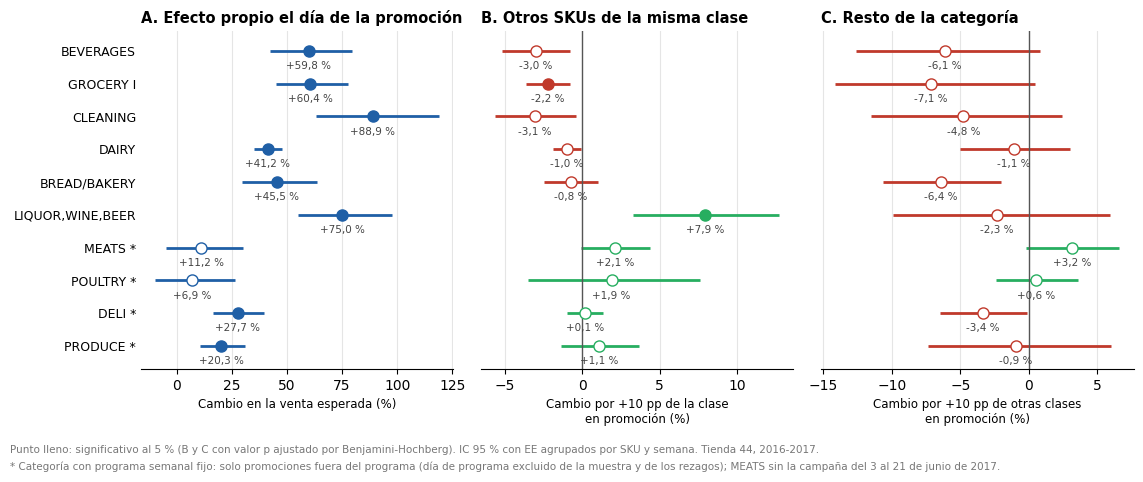

In [12]:
def datos_panel(variable: str) -> pd.DataFrame:
    """
    Esta función junta, para una variable, el efecto en % y su intervalo de 95 % por categoría. Las proporciones S
    se expresan por +10 puntos porcentuales.

    :param variable:    el nombre del coeficiente (p. ej., 'onpromotion').
    :return:            un DataFrame con una fila por categoría y las columnas efecto, inferior, superior y p.
    """

    d = coeficientes.loc[coeficientes["coeficiente"] == variable].set_index("categoria").loc[categorias]
    escala = 0.1 if variable.startswith("promo_") else 1.0
    return pd.DataFrame(
        {
            "efecto": 100 * np.expm1(escala * d["beta"]),
            "inferior": 100 * np.expm1(escala * d["ic_inf"]),
            "superior": 100 * np.expm1(escala * d["ic_sup"]),
            "p": d["p_criterio"],
        }
    )


paneles = [
    ("A. Efecto propio el día de la promoción", "onpromotion", "Cambio en la venta esperada (%)"),
    ("B. Otros SKUs de la misma clase", "promo_clase_otros", "Cambio por +10 pp de la clase\nen promoción (%)"),
    ("C. Resto de la categoría", "promo_cat_otras_clases", "Cambio por +10 pp de otras clases\nen promoción (%)"),
]

fig, ejes = plt.subplots(1, 3, figsize=(11.5, 4.8), sharey=True)
posiciones = np.arange(len(categorias))[::-1]   # la primera categoría arriba

for indice, (eje, (titulo, variable, etiqueta)) in enumerate(zip(ejes, paneles)):
    d = datos_panel(variable)
    for posicion, categoria in zip(posiciones, categorias):
        fila = d.loc[categoria]
        if indice == 0:
            color = color_neutro
        else:
            color = color_positivo if fila["efecto"] > 0 else color_negativo
        relleno = color if fila["p"] < 0.05 else "white"
        eje.hlines(posicion, fila["inferior"], fila["superior"], color=color, linewidth=2)
        eje.plot(fila["efecto"], posicion, "o", markersize=8, color=color, markerfacecolor=relleno, zorder=3)
        eje.annotate(formato_pct(fila["efecto"]), (fila["efecto"], posicion), textcoords="offset points",
                     xytext=(0, -13), ha="center", fontsize=7.5, color="#444444")
    if indice > 0:
        eje.axvline(0, color="#555555", linewidth=1)
    eje.set_title(titulo, loc="left", fontsize=10.5, fontweight="bold")
    eje.set_xlabel(etiqueta, fontsize=8.5)
    eje.set_yticks(posiciones, [etiquetas[c] for c in categorias], fontsize=9)
    eje.set_ylim(-0.7, len(categorias) - 0.4)
    eje.grid(axis="x", color="#e5e5e5")
    eje.set_axisbelow(True)
    eje.spines[["top", "right", "left"]].set_visible(False)
    eje.tick_params(axis="y", length=0)

fig.text(0.01, 0.045, "Punto lleno: significativo al 5 % (B y C con valor p ajustado por Benjamini-Hochberg). "
         "IC 95 % con EE agrupados por SKU y semana. Tienda 44, 2016-2017.", fontsize=7.5, color="#777777")
fig.text(0.01, 0.01, nota_programa, fontsize=7.5, color="#777777")
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(os.path.join(ruta_figuras, f"{prefijo}_grafico_efectos.png"), dpi=300)
plt.show()

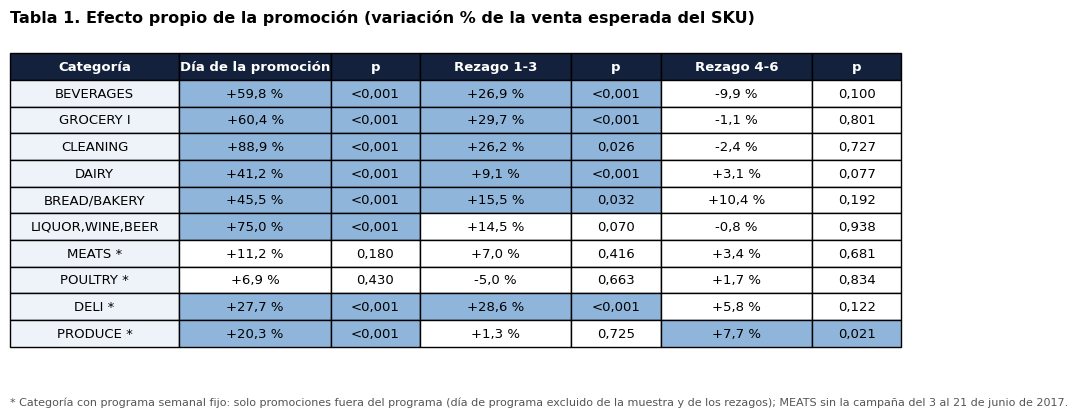

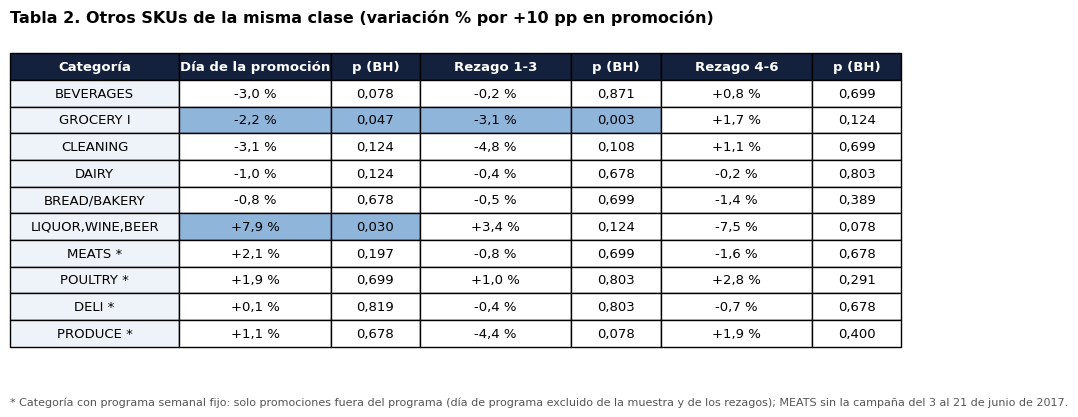

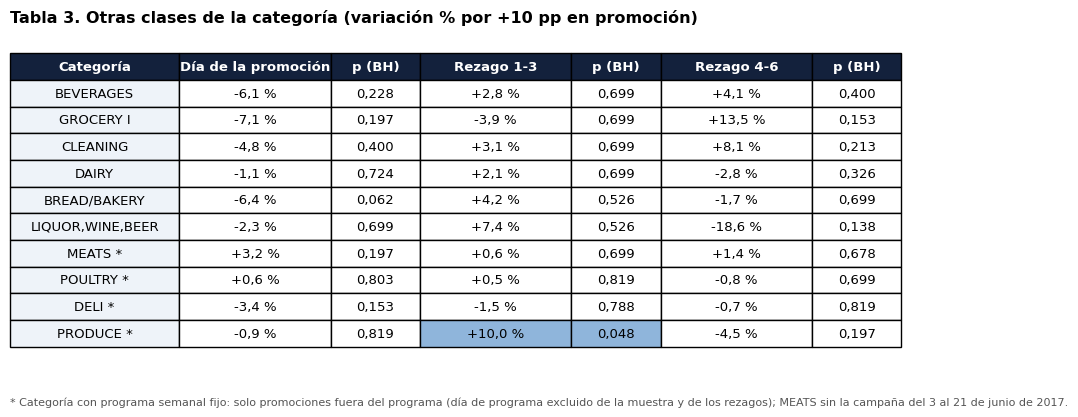

In [13]:
def dibujar_tabla(textos: list, colores: list, cabeceras: list, anchos: list, titulo: str, nombre_archivo: str) -> None:
    """
    Esta función dibuja una tabla con el formato de 06_figuras_poster, con la nota de las categorías con programa
    al pie, y la guarda como PNG.

    :param textos:          una lista de filas, cada una una lista con los textos de las celdas.
    :param colores:         una lista de filas con el color de fondo de cada celda.
    :param cabeceras:       los títulos de las columnas.
    :param anchos:          el ancho relativo de cada columna.
    :param titulo:          el título de la tabla.
    :param nombre_archivo:  el nombre del PNG, sin extensión.
    """

    fig, eje = plt.subplots(figsize=(11.5, 0.4 * (len(textos) + 1)))
    eje.axis("off")
    tabla = eje.table(cellText=textos, cellColours=colores, colLabels=cabeceras, colWidths=anchos, loc="center",
                      cellLoc="center")
    tabla.auto_set_font_size(False)
    tabla.set_fontsize(9.5)
    tabla.scale(1, 1.6)
    for j in range(len(cabeceras)):
        tabla[0, j].set_facecolor(color_cabecera)
        tabla[0, j].set_text_props(color="white", fontweight="bold")
    eje.set_title(titulo, loc="left", fontsize=11.5, fontweight="bold")
    eje.text(0.0, -0.08, nota_programa, transform=eje.transAxes, fontsize=8, color="#555555", va="top")
    fig.savefig(os.path.join(ruta_figuras, nombre_archivo + ".png"), dpi=300, bbox_inches="tight")
    plt.show()


def guardar_tabla(variable: str, titulo: str, nombre_archivo: str) -> None:
    """
    Esta función arma la tabla de un tipo de promoción (día, rezago 1-3 y rezago 4-6), igual que en
    06_figuras_poster, y la guarda como PNG.

    :param variable:        el nombre base del coeficiente (p. ej., 'onpromotion').
    :param titulo:          el título de la tabla.
    :param nombre_archivo:  el nombre del PNG, sin extensión.
    """

    c = coeficientes.set_index(["categoria", "coeficiente"])
    columna_efecto = "efecto_10pp_pct" if variable.startswith("promo_") else "efecto_pct"
    nombre_p = "p (BH)" if variable.startswith("promo_") else "p"

    # Armar los textos y los colores de las celdas
    textos, colores = [], []
    for categoria in categorias:
        fila_texto, fila_color = [etiquetas[categoria]], ["#eef3f9"]
        for sufijo in ["", "_l1_3", "_l4_6"]:
            r = c.loc[(categoria, variable + sufijo)]
            p = r["p_criterio"]
            fila_texto += [formato_pct(r[columna_efecto]), formato_p(p)]
            fila_color += [color_significativo if p < 0.05 else "white"] * 2
        textos.append(fila_texto)
        colores.append(fila_color)

    cabeceras = ["Categoría", "Día de la promoción", nombre_p, "Rezago 1-3", nombre_p, "Rezago 4-6", nombre_p]
    anchos = [0.19] + [0.17, 0.10] * 3
    dibujar_tabla(textos, colores, cabeceras, anchos, titulo, nombre_archivo)


guardar_tabla("onpromotion", "Tabla 1. Efecto propio de la promoción (variación % de la venta esperada del SKU)",
              f"{prefijo}_tabla1_efecto_propio")
guardar_tabla("promo_clase_otros", "Tabla 2. Otros SKUs de la misma clase (variación % por +10 pp en promoción)",
              f"{prefijo}_tabla2_misma_clase")
guardar_tabla("promo_cat_otras_clases", "Tabla 3. Otras clases de la categoría (variación % por +10 pp en promoción)",
              f"{prefijo}_tabla3_otras_clases")

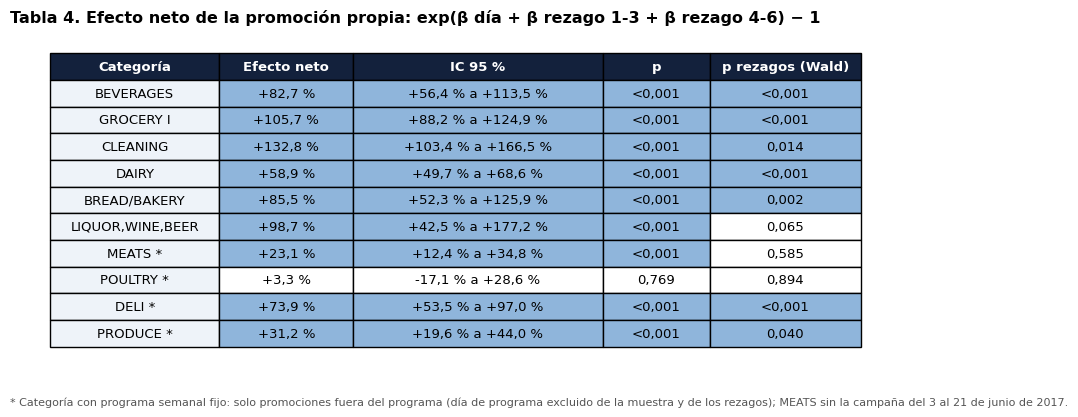


>>>> Proceso finalizado <<<<


In [14]:
# Tabla 4: efecto neto de la promoción propia y prueba conjunta de los rezagos
neto = efectos_netos.set_index("categoria")
textos, colores = [], []
for categoria in categorias:
    r = neto.loc[categoria]
    intervalo = f"{formato_pct(r['ic_inf_pct'])} a {formato_pct(r['ic_sup_pct'])}"
    textos.append([etiquetas[categoria], formato_pct(r["efecto_neto_pct"]), intervalo, formato_p(r["p_valor"]),
                   formato_p(r["p_wald_rezagos"])])
    colores.append(["#eef3f9"]
                   + [color_significativo if r["p_valor"] < 0.05 else "white"] * 3
                   + [color_significativo if r["p_wald_rezagos"] < 0.05 else "white"])

cabeceras = ["Categoría", "Efecto neto", "IC 95 %", "p", "p rezagos (Wald)"]
anchos = [0.19, 0.15, 0.28, 0.12, 0.17]
dibujar_tabla(textos, colores, cabeceras, anchos,
              "Tabla 4. Efecto neto de la promoción propia: exp(β día + β rezago 1-3 + β rezago 4-6) − 1",
              f"{prefijo}_tabla4_efecto_neto")

print(f"\n>>>> Proceso finalizado <<<<")

## Paso 10. Cómo leer estos resultados

1. **Categorías con programa (\*).** Los efectos se refieren solo a las promociones **fuera** del programa. El efecto del programa semanal no se puede estimar con estos datos (D‑26) y no debe presentarse como nulo. El rastro que deja el programa en los días siguientes lo absorbe el efecto fijo de día de la semana, lo que supone que ese rastro es igual todas las semanas.
2. **Poca información en algunas categorías.** Revisen la columna `sku_dias_promo` de `fase1v2_coeficientes.csv`: POULTRY y MEATS (sin la campaña) tienen solo unos cientos de SKU‑días en promoción fuera del programa. Un efecto no significativo ahí es falta de información, no ausencia de efecto.
3. **Efecto neto.** Suma efectos en logaritmos de distintos días; no es el cambio % de las ventas de la semana.
4. **Comparación con `05_fase1`.** Si se presenta esta versión, hay que explicar el cambio (Paso 3) y que la aprobó el profesor guía.

*Escriban aquí su interpretación.*